In [ ]:
#!pip install gymnasium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gymnasium]


# Taxi Route Optimization Using Q-Learning

**24DS742 Reinforcement Learning: Lab Assignment 5 **

Prabhu Tejas 

(BL.EN.R4AIE26008) 

Faculty: Prof. Bharath 

Amrita School of Computing, Bengaluru



| Section | Lab 5 task |
|---|---|
| 1. Application | Task 1: select an RL application |
| 2. Environment and RL formulation | Task 2: formulate the problem |
| 3. Q-learning | Task 3: algorithm exploration |
| 4. Training | Task 4: execute the application |
| 5. Performance analysis | Task 5: learning curve and analysis |
| 6. Demonstration | Task 6: demonstrate the trained agent |
| 7. Observations and conclusion | Tasks 5 and 6 |

In [2]:
%matplotlib inline
from __future__ import annotations

import time
from collections import deque
from dataclasses import dataclass
from typing import Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import clear_output

plt.rcParams.update({"figure.dpi": 110})
print("numpy", np.__version__)

numpy 2.3.5


## 1. Application (Task 1)

**Domain.** 

Taxi route optimization is a pickup-and-delivery problem: reach a customer, pick up them and carry them to their destination with as little travel as possible. The Taxi grid world (Dietterich, 2000; maintained in Gymnasium) keeps this decision structure in a form small enough to study exactly.

**Problem.** A taxi starts in a random cell of a 5×5 grid with internal walls. A passenger waits at one of four landmarks (Red, Green, Yellow, Blue) and wants to go to a different landmark.

**Objective of the agent.** Maximise total reward: deliver the passenger in the fewest moves, without illegal pickup or drop-off attempts. No route is programmed in advance.

In [3]:
N_STATES = 500
N_ACTIONS = 6
MAX_STEPS = 200
LANDMARKS: Dict[int, Tuple[int, int]] = {0: (0, 0), 1: (0, 4), 2: (4, 0), 3: (4, 3)}   # Red, Green, Yellow, Blue
LANDMARK_NAMES = {0: "Red", 1: "Green", 2: "Yellow", 3: "Blue", 4: "In taxi"}
ACTION_NAMES = {0: "South", 1: "North", 2: "East", 3: "West", 4: "Pickup", 5: "Drop-off"}
# EAST_ALLOWED[r][c] is True when the taxi can move from (r, c) to (r, c+1); False = a wall.
#   +---------+
#   |R: | : :G|
#   | : | : : |
#   | : : : : |
#   | | : | : |
#   |Y| : |B: |
#   +---------+
EAST_ALLOWED = [
    [True, False, True, True],
    [True, False, True, True],
    [True, True, True, True],
    [False, True, False, True],
    [False, True, False, True],
]

# chart colours
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
C_INK, C_MUTED, C_GRID = "#0b0b0b", "#52514e", "#e4e3df"
LANDMARK_COLORS = {0: "#C0392B", 1: "#239B56", 2: "#D4AC0D", 3: "#2471A3"}

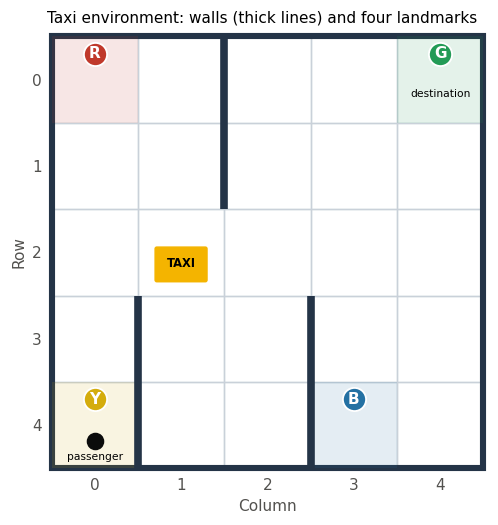

In [4]:
def style_axes(ax) -> None:
    ax.grid(True, color=C_GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b9b8b2")
    ax.tick_params(colors=C_MUTED, labelsize=9)
    ax.xaxis.label.set_color(C_MUTED)
    ax.yaxis.label.set_color(C_MUTED)

def draw_grid(ax) -> None:
    """Draw the 5x5 map: cells, walls, landmarks. Row 0 is at the top."""
    for r in range(5):
        for c in range(5):
            ax.add_patch(Rectangle((c, 4 - r), 1, 1, fill=False, edgecolor="#C9D1D9", linewidth=0.9))
    ax.add_patch(Rectangle((0, 0), 5, 5, fill=False, edgecolor="#243447", linewidth=4))
    for r in range(5):
        for c in range(4):
            if not EAST_ALLOWED[r][c]:
                ax.plot([c + 1, c + 1], [4 - r, 5 - r], color="#243447", linewidth=5, solid_capstyle="butt")
    for loc, (r, c) in LANDMARKS.items():
        ax.add_patch(Rectangle((c, 4 - r), 1, 1, color=LANDMARK_COLORS[loc], alpha=0.12, linewidth=0))
        ax.scatter(c + 0.5, 4 - r + 0.80, s=230, color=LANDMARK_COLORS[loc], edgecolors="white",
                   linewidth=1.2, zorder=4)
        ax.text(c + 0.5, 4 - r + 0.80, LANDMARK_NAMES[loc][0], color="white", fontsize=10,
                ha="center", va="center", fontweight="bold", zorder=5)
    ax.set_xlim(-0.05, 5.05)
    ax.set_ylim(-0.05, 5.05)
    ax.set_xticks(np.arange(0.5, 5, 1), labels=["0", "1", "2", "3", "4"])
    ax.set_yticks(np.arange(0.5, 5, 1), labels=["4", "3", "2", "1", "0"])
    ax.tick_params(length=0, colors=C_MUTED)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xlabel("Column", color=C_MUTED)
    ax.set_ylabel("Row", color=C_MUTED)
    ax.set_aspect("equal")


# The application: the grid, walls and landmarks, with an example situation.
fig, ax = plt.subplots(figsize=(5.2, 5.2))
draw_grid(ax)
ax.add_patch(FancyBboxPatch((1.22, 2.18), 0.56, 0.36, boxstyle="round,pad=0.02", color="#F4B400", zorder=6))
ax.text(1.5, 2.36, "TAXI", fontsize=7.5, ha="center", va="center", fontweight="bold", zorder=7)
ax.scatter(0.5, 0.32, s=110, color=C_INK, zorder=6); ax.text(0.5, 0.1, "passenger", fontsize=7, ha="center")
ax.text(4.5, 4.3, "destination", fontsize=7, ha="center")
ax.set_title("Taxi environment: walls (thick lines) and four landmarks", loc="left", fontsize=10)
plt.show()

## 2. Environment and RL formulation (Task 2)

| Component | Specification |
|---|---|
| **Agent** | Taxi controller; chooses one of six actions each step |
| **Environment** | 5×5 grid, fixed walls, landmarks R (0,0), G (0,4), Y (4,0), B (4,3); deterministic |
| **State space** | 500 states = 25 taxi cells × 5 passenger locations (4 landmarks or *in taxi*) × 4 destinations; $s = ((\text{row}\cdot5+\text{col})\cdot5+\text{passenger})\cdot4+\text{destination}$; 300 valid start states |
| **Action space** | 0 South, 1 North, 2 East, 3 West, 4 Pickup, 5 Drop-off |
| **Reward** | −1 per step; +20 for drop-off at the destination; −10 for an illegal pickup or drop-off; bumping a wall costs −1 |
| **Terminal condition** | Successful delivery. A 200-step cap **truncates** an episode but is not a terminal state |
| **Goal** | Maximise discounted return: deliver in the fewest actions, with no illegal actions |

The environment below is my own implementation of the Gymnasium Taxi dynamics.

In [5]:
@dataclass
class StepResult:
    state: int
    reward: float
    terminated: bool
    info: dict

class LocalTaxiEnv:
    """Taxi grid world with the Taxi-v3 state encoding, dynamics and rewards."""

    def __init__(self, seed: int = 42):
        self.rng = np.random.default_rng(seed)
        self.taxi_row = 0
        self.taxi_col = 0
        self.passenger_loc = 0  # 0..3 = landmark, 4 = inside the taxi
        self.destination = 1
        self.steps = 0

    @staticmethod
    def encode(row: int, col: int, passenger_loc: int, destination: int) -> int:
        return ((row * 5 + col) * 5 + passenger_loc) * 4 + destination

    @staticmethod
    def decode(state: int) -> Tuple[int, int, int, int]:
        destination = state % 4
        state //= 4
        passenger_loc = state % 5
        state //= 5
        col = state % 5
        row = state // 5
        return row, col, passenger_loc, destination

    @property
    def state(self) -> int:
        return self.encode(self.taxi_row, self.taxi_col, self.passenger_loc, self.destination)

    def set_state(self, state: int) -> None:
        self.taxi_row, self.taxi_col, self.passenger_loc, self.destination = self.decode(state)
        self.steps = 0

    def reset(self) -> Tuple[int, dict]:
        self.taxi_row = int(self.rng.integers(0, 5))
        self.taxi_col = int(self.rng.integers(0, 5))
        self.passenger_loc = int(self.rng.integers(0, 4))
        options = [loc for loc in range(4) if loc != self.passenger_loc]
        self.destination = int(self.rng.choice(options))
        self.steps = 0
        return self.state, {"success": False, "illegal_action": False}

    def step(self, action: int) -> StepResult:
        if action < 0 or action >= N_ACTIONS:
            raise ValueError(f"action must be in [0, {N_ACTIONS - 1}], received {action}")

        reward = -1.0
        terminated = False
        illegal = False
        taxi_loc = (self.taxi_row, self.taxi_col)

        if action == 0:  # south
            self.taxi_row = min(self.taxi_row + 1, 4)
        elif action == 1:  # north
            self.taxi_row = max(self.taxi_row - 1, 0)
        elif action == 2:  # east, respecting the fixed walls
            if self.taxi_col < 4 and EAST_ALLOWED[self.taxi_row][self.taxi_col]:
                self.taxi_col += 1
        elif action == 3:  # west
            if self.taxi_col > 0 and EAST_ALLOWED[self.taxi_row][self.taxi_col - 1]:
                self.taxi_col -= 1
        elif action == 4:  # pickup
            if self.passenger_loc < 4 and taxi_loc == LANDMARKS[self.passenger_loc]:
                self.passenger_loc = 4
            else:
                reward = -10.0
                illegal = True
        elif action == 5:  # drop-off
            if self.passenger_loc == 4 and taxi_loc == LANDMARKS[self.destination]:
                self.passenger_loc = self.destination
                reward = 20.0
                terminated = True
            elif self.passenger_loc == 4 and taxi_loc in LANDMARKS.values():
                # Passenger set down at a different landmark: legal, but not a delivery.
                self.passenger_loc = [k for k, v in LANDMARKS.items() if v == taxi_loc][0]
            else:
                reward = -10.0
                illegal = True

        self.steps += 1
        return StepResult(self.state, reward, terminated,
                          {"success": terminated, "illegal_action": illegal, "steps": self.steps})

    def state_tuple(self, state: int | None = None) -> Tuple[int, int, int, int]:
        return self.decode(self.state if state is None else state)

In [6]:
# Sanity checks on the environment
env = LocalTaxiEnv(seed=0)
assert all(LocalTaxiEnv.encode(*LocalTaxiEnv.decode(s)) == s for s in range(N_STATES)), "encode/decode mismatch"

s = LocalTaxiEnv.encode(0, 0, 0, 1)          # taxi on Red, passenger waiting at Red, destination Green
env.set_state(s); r1 = env.step(4)            # pickup -> legal
env.set_state(s); r2 = env.step(5)            # drop-off with no passenger -> illegal
env.set_state(LocalTaxiEnv.encode(0, 4, 4, 1)); r3 = env.step(5)   # passenger in taxi, at Green -> delivered
env.set_state(LocalTaxiEnv.encode(0, 1, 0, 1)); r4 = env.step(2)   # east from (0,1) hits a wall
print("pickup at Red        : reward", r1.reward, "| passenger now", LANDMARK_NAMES[env.decode(r1.state)[2]])
print("illegal drop-off     : reward", r2.reward)
print("delivery at Green    : reward", r3.reward, "| terminated", r3.terminated)
print("east into a wall     : reward", r4.reward, "| taxi stays at", env.decode(r4.state)[:2])

pickup at Red        : reward -1.0 | passenger now In taxi
illegal drop-off     : reward -10.0
delivery at Green    : reward 20.0 | terminated True
east into a wall     : reward -1.0 | taxi stays at (0, 1)


In [9]:
# Optional: compare all 3,000 state-action transitions with Gymnasium's own Taxi table.
try:
    import gymnasium as gym
    env_id = "Taxi-v4" if "Taxi-v4" in gym.registry else "Taxi-v3"
    P = gym.make(env_id).unwrapped.P
    local, mismatches = LocalTaxiEnv(), 0
    for s in range(N_STATES):
        for a in range(N_ACTIONS):
            (_, nxt, rew, done), = P[s][a]
            local.set_state(s); res = local.step(a)
            mismatches += (res.state, res.reward, res.terminated) != (nxt, float(rew), bool(done))
    print(f"Gymnasium {gym.__version__} ({env_id}): 3000 transitions checked, {mismatches} mismatches")
except ImportError:
    print("gymnasium not installed - skipping (pip install gymnasium to run this check)")

Gymnasium 1.4.0 (Taxi-v4): 3000 transitions checked, 0 mismatches


## 3. Algorithm: tabular Q-learning (Task 3)

**Working principle.** Q-learning (Watkins & Dayan, 1992) learns an action-value table $Q(s,a)$: the expected discounted return from taking action $a$ in state $s$ and acting optimally afterwards. After each step it moves the estimate towards a one-step target:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,\big]$$

On a delivery (a true terminal state) the target is just $r$. When the 200-step cap cuts an episode short, the update still bootstraps from $s'$, because a time limit is not a terminal state of the task (Pardo et al., ICML 2018).

**Why it suits this problem.** The state and action spaces are small and discrete (500 × 6 = 3,000 values), so an exact table works and no neural network (DQN) is needed. It is model-free. It is off-policy: it learns the greedy policy while behaving ε-greedily.

**Major parameters.** α = 0.10, γ = 0.99, ε decays linearly from 1.0 to 0.05 over the first 80% of 5,000 episodes, Q initialised to 0, ties broken at random, seed 42.

In [10]:
def epsilon_for_episode(episode: int, n_episodes: int, eps_start: float = 1.0,
                        eps_end: float = 0.05, decay_fraction: float = 0.8) -> float:
    """Linear decay from eps_start to eps_end over the first `decay_fraction` of training."""
    decay_episodes = max(1, int(n_episodes * decay_fraction))
    fraction = min(1.0, episode / decay_episodes)
    return eps_start + fraction * (eps_end - eps_start)

def greedy_action(q_row: np.ndarray, rng: np.random.Generator) -> int:
    """argmax with random tie-breaking, so untrained (all-zero) rows are not biased to action 0."""
    best = np.flatnonzero(np.isclose(q_row, np.max(q_row)))
    return int(rng.choice(best))

def choose_action(q_table: np.ndarray, state: int, epsilon: float,
                  rng: np.random.Generator) -> int:
    """epsilon-greedy behaviour policy."""
    if rng.random() < epsilon:
        return int(rng.integers(0, N_ACTIONS))
    return greedy_action(q_table[state], rng)

def train_q_learning(n_episodes: int = 5000, alpha: float = 0.10, gamma: float = 0.99,
                     seed: int = 42, max_steps: int = MAX_STEPS, log_every: int = 0,
                     log_fn=print, checkpoint_every: int = 0, checkpoint_fn=None):
    """Train a tabular Q-learning agent.

    Q(s,a) <- Q(s,a) + alpha * [r + gamma * max_a' Q(s',a') - Q(s,a)]
    On a terminal transition (delivery) the target is r; at the 200-step time limit the
    rollout is cut but the update still bootstraps, because truncation is not a terminal state.
    """
    rng = np.random.default_rng(seed)
    env = LocalTaxiEnv(seed=seed + 1)
    q_table = np.zeros((N_STATES, N_ACTIONS), dtype=np.float64)
    records: List[dict] = []

    for episode in range(1, n_episodes + 1):
        state, _ = env.reset()
        epsilon = epsilon_for_episode(episode - 1, n_episodes)
        episode_return = 0.0
        illegal_actions = 0
        success = False
        steps_taken = 0

        for step_i in range(1, max_steps + 1):
            action = choose_action(q_table, state, epsilon, rng)
            transition = env.step(action)
            next_state, reward, terminated = transition.state, transition.reward, transition.terminated
            # Only a real delivery is terminal (target = r). Hitting the 200-step cap merely truncates the
            # rollout: s' is an ordinary state, so we still bootstrap from it (Pardo et al., ICML 2018).
            truncated = (step_i == max_steps and not terminated)
            target = reward if terminated else reward + gamma * np.max(q_table[next_state])
            q_table[state, action] += alpha * (target - q_table[state, action])

            episode_return += reward
            illegal_actions += int(transition.info["illegal_action"])
            state = next_state
            steps_taken = step_i
            if terminated:
                success = True
                break
            if truncated:
                break

        records.append({
            "episode": episode,
            "epsilon": epsilon,
            "return": float(episode_return),
            "steps": steps_taken,
            "success": int(success),
            "illegal_actions": illegal_actions,
        })

        if log_every and episode % log_every == 0:
            window = records[-log_every:]
            log_fn(f"  episode {episode:5d} | eps={epsilon:4.2f} | "
                   f"mean return (last {log_every}) = {np.mean([r['return'] for r in window]):8.2f} | "
                   f"success = {100 * np.mean([r['success'] for r in window]):5.1f}% | "
                   f"mean steps = {np.mean([r['steps'] for r in window]):6.1f} | "
                   f"illegal/ep = {np.mean([r['illegal_actions'] for r in window]):5.2f}")
        if checkpoint_every and checkpoint_fn and episode % checkpoint_every == 0:
            checkpoint_fn(episode, q_table)

    return q_table, records

def evaluate(q_table: np.ndarray, n_episodes: int = 500, seed: int = 2026,
             max_steps: int = MAX_STEPS, random_policy: bool = False) -> dict:
    """Evaluate the greedy policy (epsilon = 0) or a uniform-random baseline.

    Both use the same environment seed, so they face the same 500 start states.
    """
    rng = np.random.default_rng(seed)
    env = LocalTaxiEnv(seed=seed + 1)
    returns, lengths, successes, illegals, starts = [], [], [], [], []

    for _ in range(n_episodes):
        state, _ = env.reset()
        starts.append(state)
        total_reward = 0.0
        illegal_count = 0
        success = False
        for step_i in range(1, max_steps + 1):
            action = int(rng.integers(0, N_ACTIONS)) if random_policy else greedy_action(q_table[state], rng)
            result = env.step(action)
            state = result.state
            total_reward += result.reward
            illegal_count += int(result.info["illegal_action"])
            if result.terminated:
                success = True
                break
        returns.append(total_reward)
        lengths.append(step_i)
        successes.append(int(success))
        illegals.append(illegal_count)

    return {
        "episodes": n_episodes,
        "mean_return": float(np.mean(returns)),
        "median_return": float(np.median(returns)),
        "success_rate": float(np.mean(successes)),
        "mean_steps": float(np.mean(lengths)),
        "mean_illegal_actions": float(np.mean(illegals)),
        "returns": returns,
        "steps": lengths,
        "successes": successes,
        "start_states": starts,
    }

def moving_average(values: np.ndarray, window: int = 100) -> np.ndarray:
    if len(values) < window:
        return np.array([])
    return np.convolve(values, np.ones(window) / window, mode="valid")

## 4. Training (Task 4)

Train for 5,000 episodes with seed 42, printing averages over each block of 500 episodes. Exploration is still on during training, so these numbers include random actions.

In [11]:
SEED, EPISODES, ALPHA, GAMMA = 42, 5000, 0.10, 0.99
t0 = time.time()
q_table, records = train_q_learning(n_episodes=EPISODES, alpha=ALPHA, gamma=GAMMA, seed=SEED,
                                    max_steps=MAX_STEPS, log_every=500)
print(f"\nTraining time: {time.time() - t0:.1f} s")

first, last = records[:100], records[-100:]
for name, block in [("first 100 episodes", first), ("last 100 episodes ", last)]:
    print(f"{name}: mean return {np.mean([r['return'] for r in block]):8.2f} | "
          f"success {100 * np.mean([r['success'] for r in block]):5.1f}% | "
          f"steps {np.mean([r['steps'] for r in block]):6.1f} | "
          f"illegal/ep {np.mean([r['illegal_actions'] for r in block]):5.2f}")

  episode   500 | eps=0.88 | mean return (last 500) =  -704.10 | success =  14.0% | mean steps =  188.0 | illegal/ep = 57.67
  episode  1000 | eps=0.76 | mean return (last 500) =  -433.48 | success =  68.0% | mean steps =  133.1 | illegal/ep = 34.96
  episode  1500 | eps=0.64 | mean return (last 500) =  -169.14 | success =  98.8% | mean steps =   63.7 | illegal/ep = 14.02
  episode  2000 | eps=0.53 | mean return (last 500) =   -78.31 | success = 100.0% | mean steps =   37.8 | illegal/ep =  6.84
  episode  2500 | eps=0.41 | mean return (last 500) =   -41.45 | success = 100.0% | mean steps =   27.3 | illegal/ep =  3.91
  episode  3000 | eps=0.29 | mean return (last 500) =   -20.87 | success = 100.0% | mean steps =   21.3 | illegal/ep =  2.29
  episode  3500 | eps=0.17 | mean return (last 500) =    -6.81 | success = 100.0% | mean steps =   17.4 | illegal/ep =  1.16
  episode  4000 | eps=0.05 | mean return (last 500) =     1.05 | success = 100.0% | mean steps =   15.0 | illegal/ep =  0.55


## 5. Performance analysis (Task 5)

### 5.1 Learning curve: reward vs. episodes

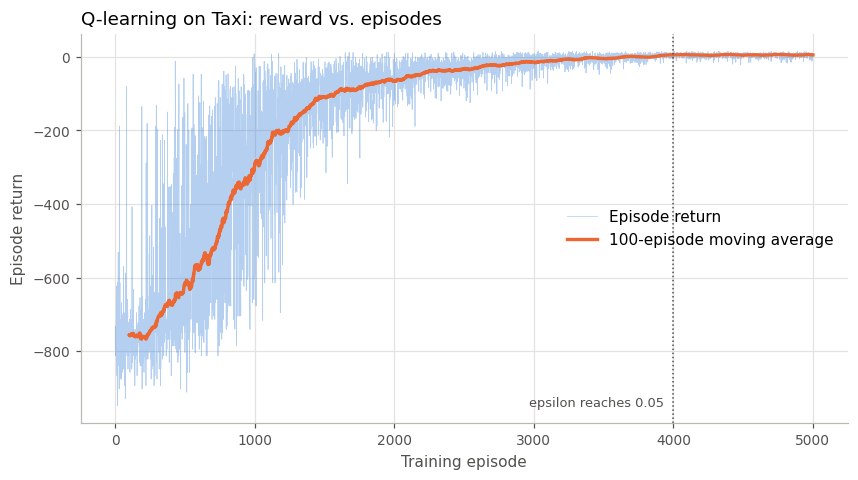

In [12]:
returns = np.array([r["return"] for r in records], dtype=float)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(np.arange(1, len(returns) + 1), returns, lw=0.5, alpha=0.35, color=C_BLUE, label="Episode return")
ax.plot(np.arange(100, len(returns) + 1), moving_average(returns), lw=2.2, color=C_ORANGE, label="100-episode moving average")
ax.axvline(0.8 * EPISODES, color=C_MUTED, ls=":", lw=1)
ax.text(0.8 * EPISODES - 40, -950, "epsilon reaches 0.05 ", color=C_MUTED, fontsize=8.5, ha="right")
ax.set_title("Q-learning on Taxi: reward vs. episodes", loc="left")
ax.set_xlabel("Training episode"); ax.set_ylabel("Episode return")
style_axes(ax); ax.legend(frameon=False, loc="center right")
plt.show()

### 5.2 Training diagnostics

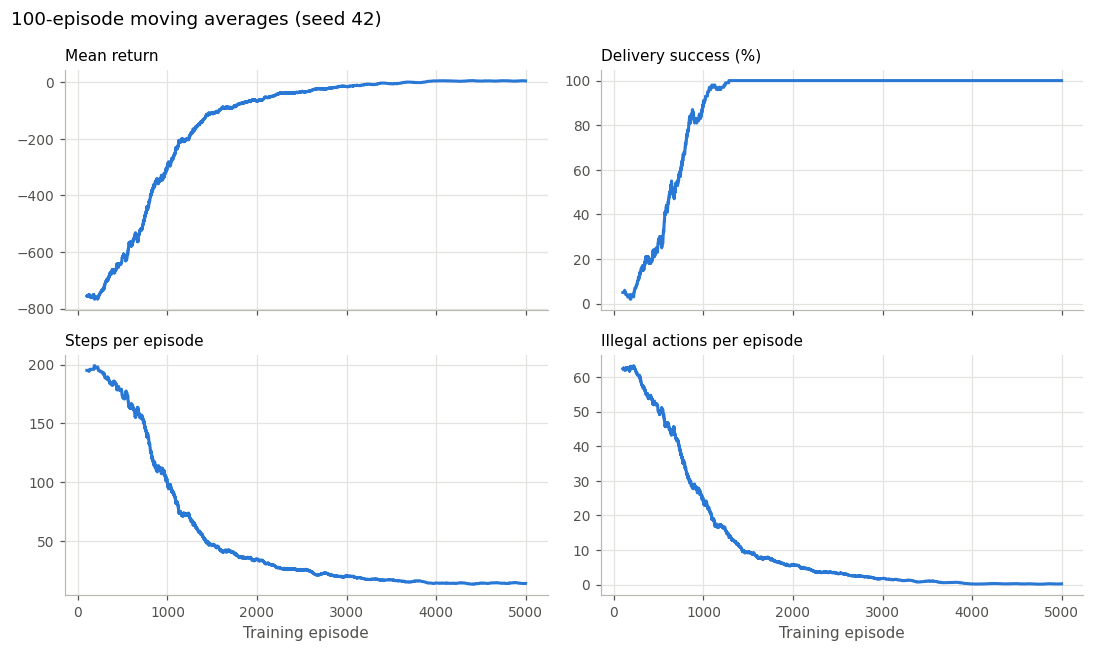

Training success first reaches 100% (100-episode window) at episode 1283


In [13]:
x = np.arange(100, len(records) + 1)
series = {
    "Mean return": moving_average(returns),
    "Delivery success (%)": 100 * moving_average(np.array([r["success"] for r in records], float)),
    "Steps per episode": moving_average(np.array([r["steps"] for r in records], float)),
    "Illegal actions per episode": moving_average(np.array([r["illegal_actions"] for r in records], float)),
}
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, (title, y) in zip(axes.ravel(), series.items()):
    ax.plot(x, y, lw=2, color=C_BLUE); ax.set_title(title, loc="left", fontsize=10); style_axes(ax)
for ax in axes[1]: ax.set_xlabel("Training episode")
fig.suptitle("100-episode moving averages (seed 42)", x=0.01, ha="left")
fig.tight_layout(); plt.show()

succ_ma = series["Delivery success (%)"]
print("Training success first reaches 100% (100-episode window) at episode", int(np.argmax(succ_ma >= 100) + 100))

### 5.3 Final performance: greedy policy vs. random baseline

Both policies are evaluated on the **same** 500 start states (evaluation seed 2026). The greedy policy uses ε = 0.

In [14]:
greedy = evaluate(q_table, n_episodes=500, seed=2026)
random_pol = evaluate(q_table, n_episodes=500, seed=2026, random_policy=True)
print(f"{'Metric':<28}{'Greedy Q-learning':>20}{'Random baseline':>18}")
for key, label in [("success_rate", "Success rate"), ("mean_return", "Mean return"), ("median_return", "Median return"),
                   ("mean_steps", "Mean steps per episode"), ("mean_illegal_actions", "Mean illegal actions")]:
    g, r = greedy[key], random_pol[key]
    fmt = (lambda v: f"{100 * v:.1f}%") if key == "success_rate" else (lambda v: f"{v:.2f}")
    print(f"{label:<28}{fmt(g):>20}{fmt(r):>18}")

Metric                         Greedy Q-learning   Random baseline
Success rate                              100.0%              3.6%
Mean return                                 7.92           -771.94
Median return                               8.00           -785.00
Mean steps per episode                     13.08            197.42
Mean illegal actions                        0.00             63.92


### 5.4 Is the learned policy optimal?

Because the dynamics are known, breadth-first search over the 500-state graph gives the true minimum number of actions from any start state. BFS is used only to **check** the agent, never to train it. We then roll out the greedy policy from **all 300** valid start states.

In [15]:
def build_transition_table():
    """Deterministic model: next_state[s, a], reward[s, a], done[s, a]."""
    env = LocalTaxiEnv()
    nxt = np.zeros((N_STATES, N_ACTIONS), dtype=int)
    rew = np.zeros((N_STATES, N_ACTIONS))
    done = np.zeros((N_STATES, N_ACTIONS), dtype=bool)
    for s in range(N_STATES):
        for a in range(N_ACTIONS):
            env.set_state(s)
            res = env.step(a)
            nxt[s, a], rew[s, a], done[s, a] = res.state, res.reward, res.terminated
    return nxt, rew, done


NEXT, REWARD, DONE = build_transition_table()


def shortest_solution_length(start: int) -> int:
    """Minimum number of actions needed to complete delivery from `start` (BFS)."""
    seen = {start}
    queue = deque([(start, 0)])
    while queue:
        s, d = queue.popleft()
        for a in range(N_ACTIONS):
            if DONE[s, a]:
                return d + 1
            n = int(NEXT[s, a])
            if n not in seen:
                seen.add(n)
                queue.append((n, d + 1))
    return -1


_SP_CACHE: Dict[int, int] = {}


def optimal_steps(state: int) -> int:
    if state not in _SP_CACHE:
        _SP_CACHE[state] = shortest_solution_length(state)
    return _SP_CACHE[state]


ALL_START_STATES = [LocalTaxiEnv.encode(r, c, p, d) for r in range(5) for c in range(5)
                    for p in range(4) for d in range(4) if p != d]


def exhaustive_optimality(q_table: np.ndarray) -> dict:
    """Roll out the deterministic greedy policy (argmax) from all 300 start states."""
    n_opt, n_succ = 0, 0
    for s0 in ALL_START_STATES:
        s, length = s0, -1
        for t in range(1, 201):
            a = int(np.argmax(q_table[s]))
            if DONE[s, a]:
                length = t
                break
            s = int(NEXT[s, a])
        n_succ += int(length > 0)
        n_opt += int(length == optimal_steps(s0))
    opt = np.array([optimal_steps(s) for s in ALL_START_STATES])
    return {"start_states": len(ALL_START_STATES), "delivered": n_succ, "optimal": n_opt,
            "expected_optimal_steps": float(opt.mean()), "expected_optimal_return": float((21 - opt).mean())}


opt_eval = np.array([optimal_steps(s) for s in greedy["start_states"]])
print(f"Evaluation set: greedy mean steps {greedy['mean_steps']:.2f} vs. BFS optimum {opt_eval.mean():.2f}; "
      f"optimal in {np.mean(np.array(greedy['steps']) == opt_eval) * 100:.1f}% of the 500 episodes")
print("All start states:", exhaustive_optimality(q_table))

Evaluation set: greedy mean steps 13.08 vs. BFS optimum 13.08; optimal in 100.0% of the 500 episodes
All start states: {'start_states': 300, 'delivered': 300, 'optimal': 300, 'expected_optimal_steps': 13.07, 'expected_optimal_return': 7.93}


### 5.5 The learned (greedy) policy during training

The training curve mixes learning with exploration noise. Here training is paused every 250 episodes and the greedy policy is evaluated on 200 fresh episodes.

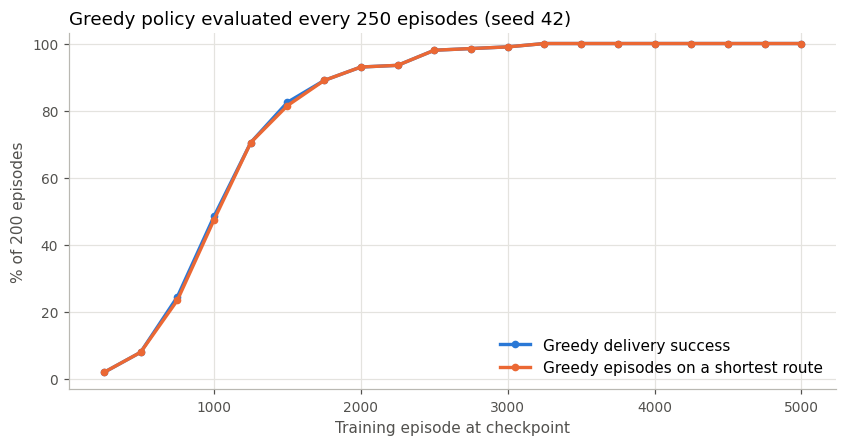

First checkpoint with 100% greedy success: 3250


In [16]:
checkpoints = []
def on_checkpoint(ep, q):
    res = evaluate(q, n_episodes=200, seed=7000 + ep)
    opt = np.array([optimal_steps(s) for s in res["start_states"]])
    on_opt = np.mean(np.array(res["successes"], bool) & (np.array(res["steps"]) == opt))
    checkpoints.append((ep, res["success_rate"], on_opt))

_ = train_q_learning(n_episodes=EPISODES, alpha=ALPHA, gamma=GAMMA, seed=SEED,
                     checkpoint_every=250, checkpoint_fn=on_checkpoint)
eps_, succ_, opt_ = map(np.array, zip(*checkpoints))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(eps_, 100 * succ_, marker="o", ms=4, lw=2.2, color=C_BLUE, label="Greedy delivery success")
ax.plot(eps_, 100 * opt_, marker="o", ms=4, lw=2.2, color=C_ORANGE, label="Greedy episodes on a shortest route")
ax.set_ylim(-3, 103); ax.set_xlabel("Training episode at checkpoint"); ax.set_ylabel("% of 200 episodes")
ax.set_title("Greedy policy evaluated every 250 episodes (seed 42)", loc="left"); style_axes(ax)
ax.legend(frameon=False, loc="lower right"); plt.show()
print("First checkpoint with 100% greedy success:", int(eps_[np.argmax(succ_ == 1.0)]))

### 5.6 Robustness across random seeds

Seed    Success  Mean steps  Optimal starts  Episodes to 95%
42       100.0%       13.08         300/300             1047
43       100.0%       13.08         300/300             1054
44       100.0%       13.08         300/300             1055
45       100.0%       13.08         300/300             1114
46       100.0%       13.08         300/300             1041
Episodes to 95% training success: 1062 ± 30


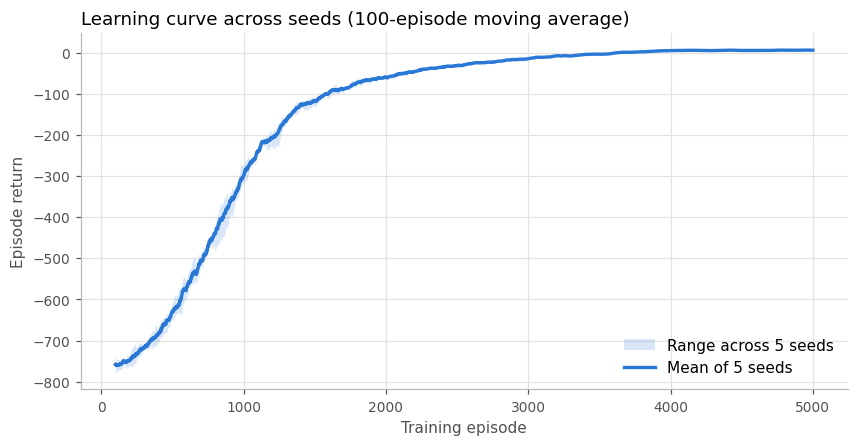

In [17]:
def convergence_episode(records: List[dict], threshold: float = 0.95, window: int = 100) -> int:
    """First episode at which the 100-episode moving training success rate reaches `threshold`."""
    ma = moving_average(np.array([r["success"] for r in records], dtype=float), window)
    hits = np.flatnonzero(ma >= threshold)
    return int(hits[0] + window) if len(hits) else -1


seed_rows, curves = [], []
for seed in [42, 43, 44, 45, 46]:
    q_s, rec_s = train_q_learning(n_episodes=EPISODES, alpha=ALPHA, gamma=GAMMA, seed=seed)
    ev = evaluate(q_s, n_episodes=500, seed=2026)
    seed_rows.append((seed, ev["success_rate"], ev["mean_steps"], exhaustive_optimality(q_s)["optimal"],
                      convergence_episode(rec_s)))
    curves.append(moving_average(np.array([r["return"] for r in rec_s], float)))

print(f"{'Seed':<6}{'Success':>9}{'Mean steps':>12}{'Optimal starts':>16}{'Episodes to 95%':>17}")
for s, sr, ms, oo, ce in seed_rows:
    print(f"{s:<6}{100 * sr:>8.1f}%{ms:>12.2f}{oo:>12}/300{ce:>17}")
conv = [r[4] for r in seed_rows]
print(f"Episodes to 95% training success: {np.mean(conv):.0f} ± {np.std(conv, ddof=1):.0f}")

curves = np.array(curves); xs = np.arange(100, curves.shape[1] + 100)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(xs, curves.min(0), curves.max(0), color=C_BLUE, alpha=0.18, lw=0, label="Range across 5 seeds")
ax.plot(xs, curves.mean(0), color=C_BLUE, lw=2.2, label="Mean of 5 seeds")
ax.set_title("Learning curve across seeds (100-episode moving average)", loc="left")
ax.set_xlabel("Training episode"); ax.set_ylabel("Episode return"); style_axes(ax)
ax.legend(frameon=False, loc="lower right"); plt.show()

### 5.7 Sensitivity to the learning rate

A quick version of the study in `experiments.py` (which covers α × γ with 3 seeds each): vary α with γ = 0.99 and seed 42.

In [18]:
print(f"{'alpha':<8}{'Greedy success':>16}{'Mean steps':>12}{'Episodes to 95%':>17}")
for a in [0.05, 0.10, 0.30, 0.50]:
    q_a, rec_a = train_q_learning(n_episodes=EPISODES, alpha=a, gamma=GAMMA, seed=SEED)
    ev = evaluate(q_a, n_episodes=500, seed=2026)
    print(f"{a:<8}{100 * ev['success_rate']:>15.1f}%{ev['mean_steps']:>12.2f}{convergence_episode(rec_a):>17}")

alpha     Greedy success  Mean steps  Episodes to 95%
0.05               96.6%       19.31             1468
0.1               100.0%       13.08             1047
0.3               100.0%       13.08              739
0.5               100.0%       13.08              864


### 5.8 What the agent learned

Greedy action per cell (arrows) and state value $\max_a Q(s,a)$ (shading), for a passenger waiting at Yellow who wants to go to Green: before pickup (left) and with the passenger on board (right).

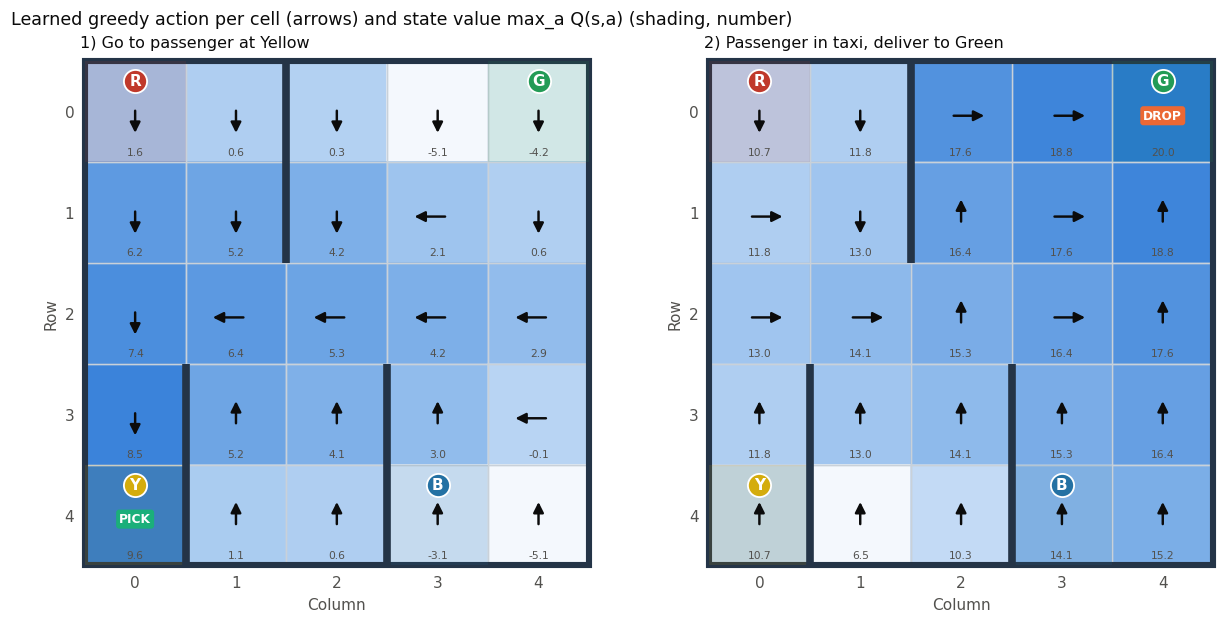

well-travelled cell    state (2, 0) before pickup: learned   7.44 | exact   7.44
rarely visited corner  state (0, 3) before pickup: learned  -5.14 | exact   2.17


In [19]:
def plot_policy_and_values(q: np.ndarray, out_path, passenger: int = 2, destination: int = 1) -> None:
    """Greedy action per cell and max-Q value, before and after pickup."""
    arrows = {0: (0, -0.2), 1: (0, 0.2), 2: (0.26, 0), 3: (-0.26, 0)}
    cmap = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#9cc3ee", "#2a78d6"])
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.6))
    phases = [(passenger, f"1) Go to passenger at {LANDMARK_NAMES[passenger]}"),
              (4, f"2) Passenger in taxi, deliver to {LANDMARK_NAMES[destination]}")]
    for ax, (ploc, title) in zip(axes, phases):
        values = np.zeros((5, 5))
        for r in range(5):
            for c in range(5):
                values[r, c] = q[LocalTaxiEnv.encode(r, c, ploc, destination)].max()
        vmin, vmax = values.min(), values.max()
        for r in range(5):
            for c in range(5):
                frac = (values[r, c] - vmin) / (vmax - vmin + 1e-9)
                ax.add_patch(plt.Rectangle((c, 4 - r), 1, 1, color=cmap(frac), zorder=0))
        draw_grid(ax)
        for r in range(5):
            for c in range(5):
                s = LocalTaxiEnv.encode(r, c, ploc, destination)
                a = int(np.argmax(q[s]))
                cx, cy = c + 0.5, 4 - r + 0.46
                if a in arrows:
                    dx, dy = arrows[a]
                    ax.annotate("", xy=(cx + dx, cy + dy), xytext=(cx - dx * 0.4, cy - dy * 0.4),
                                arrowprops=dict(arrowstyle="-|>", color=C_INK, lw=1.6, mutation_scale=14), zorder=8)
                else:
                    ax.text(cx, cy, "PICK" if a == 4 else "DROP", ha="center", va="center", fontsize=8,
                            fontweight="bold", color="white", zorder=8,
                            bbox=dict(boxstyle="round,pad=0.25", fc=C_ORANGE if a == 5 else C_AQUA, ec="none"))
                ax.text(c + 0.5, 4 - r + 0.05, f"{values[r, c]:.1f}", ha="center", va="bottom", fontsize=7,
                        color=C_MUTED, zorder=8)
        ax.set_title(title, loc="left", fontsize=10.5, color=C_INK)
    fig.suptitle("Learned greedy action per cell (arrows) and state value max_a Q(s,a) (shading, number)",
                 x=0.01, ha="left", fontsize=11.5, color=C_INK)
    fig.tight_layout()
    plt.show()


plot_policy_and_values(q_table, None)

# Compare learned values with exact values from value iteration
Q_true = np.zeros((N_STATES, N_ACTIONS))
for _ in range(2000):
    Q_true = REWARD + 0.99 * np.where(DONE, 0, Q_true.max(1)[NEXT])
for (r, c, p, d), label in [((2, 0, 2, 1), "well-travelled cell"), ((0, 3, 2, 1), "rarely visited corner")]:
    s = LocalTaxiEnv.encode(r, c, p, d)
    print(f"{label:<22} state {(r, c)} before pickup: learned {q_table[s].max():6.2f} | exact {Q_true[s].max():6.2f}")

Values on well-travelled routes match the exact values, while rarely visited corners are still underestimated. The policy is optimal anyway, because acting well needs only the *ranking* of actions in each state to be right, not every value.

## 6. Demonstration (Task 6)

### 6.1 One greedy episode drawn on the grid

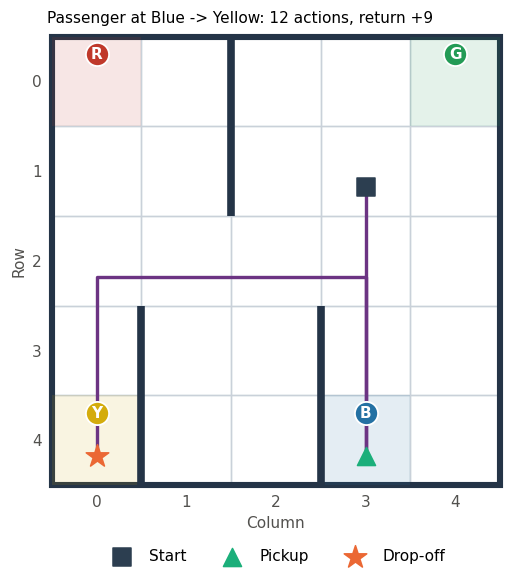

Actions: South -> South -> South -> Pickup -> North -> North -> West -> West -> West -> South -> South -> Drop-off


In [20]:
def show_greedy_episode(q, seed=9001):
    env = LocalTaxiEnv(seed=seed)
    state, _ = env.reset()
    r0, c0, p0, d0 = env.state_tuple(state)
    path, total, actions, pickup_at = [(r0, c0)], 0.0, [], None
    for _ in range(MAX_STEPS):
        best = np.flatnonzero(np.isclose(q[state], q[state].max()))
        a = int(best.min()); actions.append(ACTION_NAMES[a])
        res = env.step(a); total += res.reward; state = res.state
        if a == 4 and not res.info["illegal_action"]:
            pickup_at = (env.taxi_row, env.taxi_col)
        path.append((env.taxi_row, env.taxi_col))
        if res.terminated:
            break
    fig, ax = plt.subplots(figsize=(5.4, 5.4))
    draw_grid(ax)
    ax.plot([c + 0.5 for r, c in path], [4 - r + 0.32 for r, c in path], color="#6C3483", lw=2.2, zorder=3)
    ax.scatter(c0 + 0.5, 4 - r0 + 0.32, s=150, marker="s", color="#2C3E50", zorder=6, label="Start")
    if pickup_at:
        ax.scatter(pickup_at[1] + 0.5, 4 - pickup_at[0] + 0.32, s=140, marker="^", color=C_AQUA, zorder=6, label="Pickup")
    ax.scatter(env.taxi_col + 0.5, 4 - env.taxi_row + 0.32, s=240, marker="*", color=C_ORANGE, zorder=7, label="Drop-off")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
    ax.set_title(f"Passenger at {LANDMARK_NAMES[p0]} -> {LANDMARK_NAMES[d0]}: {len(actions)} actions, return {total:+.0f}",
                 loc="left", fontsize=10)
    plt.show()
    print("Actions:", " -> ".join(actions))

show_greedy_episode(q_table)

### 6.2 Live demo

Plays a greedy episode step by step, showing the board, the six Q-values and the chosen action. Set `untrained=True` to watch an all-zero Q-table (no learning) get stuck.

In [21]:
def render(env):
    row, col, ploc, dest = env.state_tuple()
    letters = {v: LANDMARK_NAMES[k][0] for k, v in LANDMARKS.items()}
    lines = ["+---------+"]
    for r in range(5):
        line = "|"
        for c in range(5):
            ch = letters.get((r, c), " ")
            if (r, c) == (row, col):
                ch = "@" if ploc == 4 else "T"
            line += ch + ((":" if EAST_ALLOWED[r][c] else "|") if c < 4 else "")
        lines.append(line + "|")
    lines += ["+---------+", f"T = empty taxi, @ = carrying passenger | passenger: {LANDMARK_NAMES[ploc]}, "
              f"destination: {LANDMARK_NAMES[dest]}"]
    return "\n".join(lines)


def live_demo(q, seed=11, delay=0.4, untrained=False, max_steps=40):
    q = np.zeros_like(q) if untrained else q
    env = LocalTaxiEnv(seed=seed)
    state, _ = env.reset()
    total = 0.0
    for t in range(1, max_steps + 1):
        a = int(np.argmax(q[state]))
        clear_output(wait=True)
        print(render(env))
        print("Q(s,.):", "  ".join(f"{ACTION_NAMES[i][:4]}={q[state, i]:6.2f}" for i in range(6)))
        res = env.step(a); total += res.reward; state = res.state
        print(f"step {t:3d} | action = {ACTION_NAMES[a]:<8} | reward = {res.reward:+4.0f} | return = {total:+5.0f}")
        time.sleep(delay)
        if res.terminated:
            clear_output(wait=True); print(render(env))
            print(f"\nDelivered in {t} actions, total reward {total:+.0f}.")
            return
    print(f"\nNot delivered within {max_steps} actions (return {total:+.0f}).")

live_demo(q_table, seed=11, delay=0.4)

+---------+
|R: | : :T|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
T = empty taxi, @ = carrying passenger | passenger: Green, destination: Green

Delivered in 14 actions, total reward +7.


In [22]:
# Contrast: the agent before learning (all-zero Q-table). Argmax ties always pick South, so it never delivers.
live_demo(q_table, seed=11, delay=0.05, untrained=True, max_steps=20)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|T| : |B: |
+---------+
T = empty taxi, @ = carrying passenger | passenger: Blue, destination: Green
Q(s,.): Sout=  0.00  Nort=  0.00  East=  0.00  West=  0.00  Pick=  0.00  Drop=  0.00
step  20 | action = South    | reward =   -1 | return =   -20

Not delivered within 20 actions (return -20).


## 7. Observations and conclusion

**Does performance improve as training progresses? Yes, and measurably.**
- The 100-episode moving-average return rises from about −760 to about +5, training success climbs to 100%, and illegal actions fall from about 60 to under 1 per episode (Sections 4 and 5.1–5.2).
- Learning happens in stages: first stop illegal pickups and drop-offs, then complete deliveries, then shorten routes until ε reaches its floor.
- The greedy policy (no exploration) improves from near 0% success to 100% (Section 5.5).

**Final performance.**
- The greedy agent delivers in every evaluation episode, with zero illegal actions and the BFS-optimal number of steps.
- It takes a shortest route from all 300 valid start states, on all 5 seeds (Sections 5.3–5.6). The random policy rarely delivers.

**Training return understates the final policy.** The last training episodes still include ε = 0.05 random actions; the same Q-table run greedily scores the optimum.

**Sensitivity.** The learning rate matters most. α = 0.05 is too slow for 5,000 episodes, and α of 0.3–0.5 converges faster than 0.1 here, which is safe only because the environment is deterministic.

**Limitations.** The grid is small, deterministic and fully observable. It does not model traffic, stochastic travel times, multiple taxis or changing demand, and tables do not scale to large state spaces (DQN would be needed).

**Link to doctoral research.** Choosing whether to continue or switch therapy in rheumatoid arthritis is the same kind of sequential decision problem (a dynamic treatment regime). There, exploring on patients is not possible, so the clinical version needs offline RL from logged data and careful off-policy evaluation. Checking against a trusted reference, as BFS does here, matters even more in that setting.

### References
1. Farama Foundation, "Taxi," Gymnasium documentation, https://gymnasium.farama.org/environments/toy_text/taxi/
2. C. J. C. H. Watkins and P. Dayan, "Q-learning," *Machine Learning*, 8, 279–292, 1992.
3. R. S. Sutton and A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press, 2018.
4. T. G. Dietterich, "Hierarchical reinforcement learning with the MAXQ value function decomposition," *JAIR*, 13, 227–303, 2000.
5. F. Pardo, A. Tavakoli, V. Levdik and P. Kormushev, "Time limits in reinforcement learning," *ICML*, PMLR 80, 2018.
6. O. Gottesman et al., "Guidelines for reinforcement learning in healthcare," *Nature Medicine*, 25, 16–18, 2019.